# Practical 1 — Instructor solutions: Can we reconstruct a temperature field without temperature measurements?

**Machine Learning for Physics 2026 - MSIAM / Ensimag**

*Author: Filippo Masi*

Problem: Imagine a heated bar whose governing equation and endpoint temperatures are known, but whose temperature inside the bar has not been measured. Can a neural network predict a physically meaningful field without any interior training labels?

In this practical, you will build a physics-informed neural network (PINN) from almost nothing: a differentiable artificial neural network ansatz function (MLP), a PDE residual, boundary information and an optimizer. The objective is to test which conditions the network actually learned and which conditions can be guaranteed by its structure.

At the end, you should be able to
- Compute first and second input derivatives through a multi-layer perceptron (MLP) using automatic differentiation.
- Train a neural network from the PDE and boundary conditions.
- Distinguish the training residual, the validation error and the boundary mismatch.
- Explain and demonstrate why soft and hard constraints are not interchangeable.

Suggestion: First run a small number of optimizer steps to debug.

Working principle: Predict what a code cell should show, complete the `TODO`s, run the assertion test, and then explain what you observed. 


## 1. Start from the physics: what information is available?

A bar occupies $0<x<1$. Its steady temperature $u(x)$ satisfies

$$-u_{xx}(x)=f(x), \qquad u(0)=u(1)=0.$$

The source $f$ describes heating along the bar while the boundary conditions fix its temperature at the two ends. To judge whether our PINN works, we choose a reference solution:

$$u_{\mathrm{exact}}(x)=\sin(\pi x),\qquad f(x)=\pi^2\sin(\pi x).$$

We are allowed to know $f$ and the two boundary temperatures during training. We will not give the network values of $u_{\mathrm{exact}}$ inside the domain. We keep that analytical solution for validation only. This is precisely what makes the problem a meaningful PINN test rather than supervised curve fitting.

- Before running the setup: Differentiate $u_{\mathrm{exact}}$ twice to verify the source.
- What information would be missing if we provided the equation but neither boundary condition?

**Answer.** Differentiating the manufactured temperature twice gives $u'_{\mathrm{exact}}(x)=\pi\cos(\pi x)$ and $u''_{\mathrm{exact}}(x)=-\pi^2\sin(\pi x)$, so indeed $-u''_{\mathrm{exact}}=f$. Without boundary conditions the equation determines $u$ only up to $ax+b$, because the second derivative of any affine function is zero. The boundary values are *not* extra observations of the interior: they are part of the definition of a well-posed boundary-value problem.

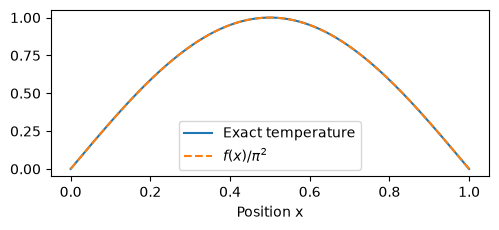

In [1]:
import time
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

# Keep the practical reproducible and reasonably quick on classroom CPUs.
torch.set_num_threads(1)
torch.set_default_dtype(torch.float32)
torch.manual_seed(13)
np.random.seed(13)
device = torch.device('cpu')
PI = np.pi


def u_exact(x):
    """Manufactured exact solution. Use for error plots, never as PINN labels."""
    return torch.sin(PI * x)


def source(x):
    """Volumetric heat source chosen to match u_exact."""
    return PI**2 * torch.sin(PI * x)

x_plot = torch.linspace(0.0, 1.0, 301).view(-1, 1)
plt.figure(figsize=(5.0, 2.4), tight_layout=True)
plt.plot(x_plot, u_exact(x_plot), label='Exact temperature')
plt.plot(x_plot, source(x_plot) / PI**2, '--', label=r'$f(x)/\pi^2$')
plt.xlabel('Position x')
plt.legend()
plt.show()

### Plotting tools

All plotting code is embedded below, so the notebook is self-contained. The analytical reference is never used as a training label!


In [2]:
def plot_poisson_report(x, reference, prediction, pde_residual, history):
    """Inspect the state, its error, the independent residual, and training losses."""
    x = np.asarray(x).ravel()
    reference = np.asarray(reference).ravel()
    prediction = np.asarray(prediction).ravel()
    residual = np.asarray(pde_residual).ravel()

    fig, axes = plt.subplots(2, 2, figsize=(8.0, 5.2), constrained_layout=True)
    ax_field, ax_error, ax_residual, ax_loss = axes.ravel()

    # The exact solution is for validation, never used as a PINN label.
    ax_field.plot(x, reference, label='Exact')
    ax_field.plot(x, prediction, '--', label='PINN')
    ax_field.set(title='temperature field', xlabel='$x$', ylabel='$u(x)$')
    ax_field.legend(fontsize=8)

    ax_error.plot(x, np.abs(prediction - reference))
    ax_error.set(title='pointwise error', xlabel='$x$', ylabel='Absolute error')

    # A fresh grid is more informative than the training residual alone.
    ax_residual.semilogy(x, np.maximum(np.abs(residual), 1e-12))
    ax_residual.set(title='held-out PDE residual', xlabel='$x$',
                    ylabel=r'$|-u_{xx}-f|$')

    # Plot losses separately: their weighted sum conceals imbalances.
    for key, label in (('pde', 'PDE'), ('bc', 'Boundary'), ('total', 'Weighted total')):
        ax_loss.semilogy(np.maximum(history[key], 1e-13), label=label)
    ax_loss.set(title='training history', xlabel='Adam iteration', ylabel='Loss')
    ax_loss.legend(fontsize=8)
    plt.show()


def plot_poisson_hard_soft(x, exact, standard, weak, hard):
    """Make the BC difference visible even when the solution curves overlap."""
    x = np.asarray(x).ravel()
    exact = np.asarray(exact).ravel()
    fields = [np.asarray(v).ravel() for v in (standard, weak, hard)]
    labels = [r'Soft $\lambda_b=10$', r'Soft $\lambda_b=10^{-3}$', 'Hard']

    fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.7), constrained_layout=True)

    axes[0].plot(x, exact, label='Exact')
    for values, name in zip(fields, labels):
        axes[0].plot(x, values, label=name)
    axes[0].set(xlabel='$x$', ylabel='$u(x)$', title='temperature profiles')
    axes[0].legend(fontsize=7)

    # Use a logarithmic scale for the state error to distinguish close curves.
    for values, name in zip(fields, labels):
        axes[1].semilogy(x, np.maximum(np.abs(values - exact), 1e-9), label=name)
    axes[1].set(xlabel='$x$', ylabel='absolute error', title='pointwise state error')

    # Plot values AT THE ENDPOINTS; whole-field curves can hide these deviations.
    # Every hard-BC endpoint is exactly zero by construction.
    locations = np.arange(len(fields))
    end_values = np.asarray([[values[0], values[-1]] for values in fields])
    axes[2].bar(locations - 0.17, end_values[:, 0], width=0.34, label='$u(0)$')
    axes[2].bar(locations + 0.17, end_values[:, 1], width=0.34, label='$u(1)$')
    axes[2].axhline(0, linestyle=':', linewidth=1)
    axes[2].set_xticks(locations, ['Soft 10', 'Soft $10^{-3}$', 'Hard'])
    axes[2].tick_params(axis='x', labelsize=7)
    axes[2].set(ylabel='temperature at the boundaries', title='boundary error')
    axes[2].legend(fontsize=7)
    plt.show()


## Exercise 1 — How does a network "know" its derivatives?

A PINN approximates the temperature by a smooth neural function $u_\theta(x)$. The PDE is about the second-order derivative $u_{xx}$, whereas an ordinary regression network is usually trained only on outputs. The missing ingredient is automatic differentiation with respect to the input coordinate.

- To do:
1. Complete `derivative(y, x)` using `torch.autograd.grad` with `grad_outputs=torch.ones_like(y)` and `create_graph=True`.
2. Differentiate the known function $\sin(\pi x)$ twice. Check both derivatives against the expressions you derived on paper.
3. Explain the difference between $\partial_x u_\theta$ (the quantity appearing in the PDE) and $\nabla_\theta L$ (the gradient used by Adam).

- What would happen to the second derivative if you detached the first derivative from the computational graph? Why would `torch.no_grad()` be inappropriate for this cell?

The two assertions pass before you have trained any network. If not, debug the differentiation code now: every later PINN loss depends on it.

In [3]:
def make_mlp(in_dim=1, width=32, out_dim=1):
    """Smooth fully connected NN (given)."""
    return nn.Sequential(
        nn.Linear(in_dim, width), nn.Tanh(),
        nn.Linear(width, width), nn.Tanh(),
        nn.Linear(width, out_dim),
    ).to(device)


def derivative(y, x):
    """Differentiate the scalar network output with respect to x."""
    
    # Differentiate with respect to the *input coordinates*, not the weights.
    # create_graph=True keeps this derivative differentiable, which is needed
    # both for second coordinate derivatives and for subsequent training.
    return torch.autograd.grad(
        outputs=y,
        inputs=x,
        grad_outputs=torch.ones_like(y),
        create_graph=True,
    )[0]

x_check = torch.linspace(0, 1, 40).view(-1, 1).requires_grad_(True)
u_check = u_exact(x_check)
u_x = derivative(u_check, x_check)
u_xx = derivative(u_x, x_check)
assert (u_x - PI*torch.cos(PI*x_check)).abs().max().item() < 1e-4
assert (-u_xx - source(x_check)).abs().max().item() < 1e-4
print('Automatic differentiation checks passed.')

Automatic differentiation checks passed.


**Answer.**

1. $\partial_x u_\theta$ and $\partial_{xx}u_\theta$ are coordinate derivatives used to assemble the physics residual. $\nabla_\theta L$ is the parameter gradient computed by backpropagation to update weights and biases. Training differentiates *through* the coordinate-derivative computation.
2. For the manufactured field, $u_x=\pi\cos(\pi x)$ and $u_{xx}=-\pi^2\sin(\pi x)$. Both assertions pass when `create_graph=True` is used.
3. Calling `.detach()` on the first derivative discards the graph needed for its second derivative. Using `torch.no_grad()` disables construction of the graph altogether. Both are inappropriate when assembling a differentiable PINN residual. For visualization of an already trained model, by contrast, `no_grad()` is appropriate.

## Exercise 2 — Train from physics, not from labeled temperatures

Knowing how to differentiate the network, we can ask it to satisfy the equation at selected collocation points $x_{f,i}$ and the two endpoint conditions at $x_b\in\{0,1\}$. Define

$$r_\theta(x)=-u_{\theta,xx}(x)-f(x),$$
$$L_f=\frac1{N_f}\sum_{i=1}^{N_f}r_\theta(x_{f,i})^2,\qquad
L_b=\tfrac12\big(u_\theta(0)^2+u_\theta(1)^2\big),$$
$$L(\theta)=L_f+\lambda_b L_b.$$

This is the simplest soft-constrained PINN: the equation and the boundary conditions are penalized through a loss, rather than being mathematically guaranteed. Remember: this is a forward problem, the reference solution does not appear in the loss.

- Implement the strong-form residual, both loss components, and the missing backpropagation/update operations in `train_poisson`. Keep the loss components separate in the history.
- Could a small $L_f$ coexist with large boundary errors? Is the total loss sufficient to answer that? Try 200 steps to debug, then the full 900-step training. Describe which loss decreases fastest, and whether resampling the collocation coordinates changes what "training points" means.

In [4]:
def poisson_losses(model, x_f, bc_weight=10.0):
    """Compute the PDE and boundary errors."""
    x_f = x_f.detach().clone().requires_grad_(True)
    u = model(x_f)
    u_x = derivative(u, x_f)
    u_xx = derivative(u_x, x_f)
    
    # Enforce the strong-form Poisson equation at collocation coordinates.
    # No interior temperature observations are used in this loss.
    residual = -u_xx - source(x_f)
    loss_pde = residual.square().mean()

    # Evaluate the network at the two physical endpoints, independently
    # of the randomly sampled interior collocation coordinates.
    x_b = x_f.new_tensor([[0.0], [1.0]])
    u_b = model(x_b)
    loss_bc = u_b.square().mean()

    # The BC weight controls a tradeoff; the two raw terms are saved
    # separately below so that they can be diagnosed later.
    total = loss_pde + bc_weight * loss_bc
    return total, loss_pde, loss_bc


def train_poisson(model, steps=900, bc_weight=10.0, n_f=64, lr=2e-3, fixed_x=None):
    """Train with resampled collocation or a supplied fixed point set.

    fixed_x is a bonus-only option. It leaves the core exercise unchanged.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    logs = {'pde': [], 'bc': [], 'total': []}
    collocation_rng = torch.Generator().manual_seed(31415)  # Repeatable across penalties.
    start = time.perf_counter()
    for epoch in range(steps):
        if fixed_x is None:
            x_f = torch.rand(n_f, 1, generator=collocation_rng, device=device)
        else:
            x_f = fixed_x  # Same PDE points at every optimizer step.
        optimizer.zero_grad()
        total, pde, bc = poisson_losses(model, x_f, bc_weight)
        # Differentiate the complete objective w.r.t. trainable weights,
        # then take one Adam update. x_f remains an input, not a parameter.
        total.backward()
        optimizer.step()

        # Record *unweighted* loss components for independent diagnostics.
        loss_pde_value = pde.detach().item()
        logs['pde'].append(loss_pde_value)
        logs['bc'].append(bc.detach().item())
        logs['total'].append(total.detach().item())

        # A sparse progress report is much easier to read than 900 lines.
        if (epoch + 1) % 300 == 0 or epoch == 0:
            print(f'Step {epoch + 1:4d}/{steps}: '
                  f'PDE={loss_pde_value:.2e}, BC={logs["bc"][-1]:.2e}, '
                  f'total={logs["total"][-1]:.2e}')
    return logs, time.perf_counter() - start

soft_model = make_mlp()

# Retain the SAME initial parameters for the weak-penalty demonstration later.
soft_initial_state = {key: value.detach().clone()
                      for key, value in soft_model.state_dict().items()}
soft_logs, soft_time = train_poisson(soft_model)
print(f'Soft-BC PINN: {soft_time:.2f} s, last loss {soft_logs["total"][-1]:.2e}')

Step    1/900: PDE=4.62e+01, BC=4.01e-02, total=4.66e+01
Step  300/900: PDE=4.97e-03, BC=1.24e-05, total=5.09e-03
Step  600/900: PDE=2.85e-03, BC=1.57e-05, total=3.00e-03
Step  900/900: PDE=1.93e-03, BC=3.34e-06, total=1.96e-03
Soft-BC PINN: 0.73 s, last loss 1.96e-03


**Answer.**

- Which information trains the PINN? The forcing $f$, PDE collocation coordinates, and the prescribed endpoint values. There are no interior solution labels in the loss.
- Could the PDE loss be small while the endpoints are wrong? Yes. Adding $ax+b$ changes boundary values without changing the second derivative; Exercise 4 and Bonus D demonstrate this explicitly.
- Why inspect terms separately? $L_f+\lambda_b L_b$ can decrease while one physically important constraint remains inaccurate. Save unweighted $L_f$ and $L_b$ as well as the weighted objective.
- What does resampling mean? Every iteration draws new approximate quadrature points for the PDE residual; the collocation set is not a fixed mesh. The individual losses can fluctuate between iterations even if optimization generally improves. The first and final printed values show that both components decreased in this run; comparing their raw numerical magnitudes is meaningful only with attention to their physical scales.

## Exercise 3 — What does "solving the PDE" actually mean?

The optimizer has only checked randomly drawn collocation coordinates.

A convincing scientific result should be evaluated independently of those draws.

Here we can do something unusually valuable: compare with an *analytical* temperature field that was never used for training.

- Complete `assess_poisson` and report three different quantities on a fresh 301-point grid:

1. Relative state error: $\|u_\theta-u_{\mathrm{exact}}\|_2/\|u_{\mathrm{exact}}\|_2$.
2. Fresh-point residual: root mean square of $-u_{\theta,xx}-f$.
3. Boundary mismatch: $\max(|u_\theta(0)|,|u_\theta(1)|)$.

- Run the provided four-panel figure: reference vs prediction, pointwise state error, held-out PDE residual, and individual loss curves.

- Which of these three metrics does the optimizer directly see? Why can a small *sampled* residual fail to certify a small state error? Identify a region where the error/residual is larger than its domain average. These questions matter much more than making the prediction line visually overlap the exact curve.

Soft: rel. L2=1.886e-03, fresh RMS residual=5.079e-02, max |BC|=2.48e-03


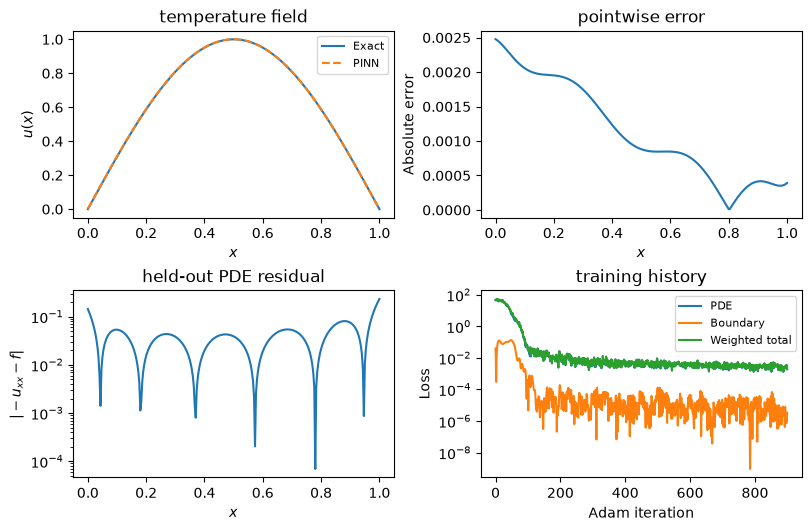

In [5]:
def assess_poisson(model):
    """Evaluate the trained network on 301 fresh points."""
    x = torch.linspace(0, 1, 301).view(-1, 1).requires_grad_(True)
    u = model(x)
    u_xx = derivative(derivative(u, x), x)
    r = -u_xx - source(x)
    
    # This analytical reference has NOT appeared anywhere in the loss.
    reference = u_exact(x)
    relative_error = torch.linalg.vector_norm(u - reference) / torch.linalg.vector_norm(reference)

    # Collocation points are resampled during training; this fixed grid
    # is independent of all training batches.
    rms_residual = torch.sqrt(torch.mean(r.square()))

    # x[0] and x[-1] are the boundaries of the fresh validation grid.
    max_bc_error = torch.max(torch.abs(u[[0, -1]]))

    # Metrics are scalar Python numbers: do not retain their AD graphs.
    return relative_error.item(), rms_residual.item(), max_bc_error.item()

soft_error, soft_residual, soft_bc_error = assess_poisson(soft_model)
print(f'Soft: rel. L2={soft_error:.3e}, fresh RMS residual={soft_residual:.3e}, max |BC|={soft_bc_error:.2e}')

with torch.no_grad():
    u_soft = soft_model(x_plot).numpy().squeeze()
# Evaluate the differential equation independently of the training batches.
# This derivative check is intentionally performed on a fresh, dense x-grid.
x_check_fresh = x_plot.detach().clone().requires_grad_(True)
u_check_fresh = soft_model(x_check_fresh)
r_check_fresh = (-derivative(derivative(u_check_fresh, x_check_fresh), x_check_fresh)
                 - source(x_check_fresh)).detach().numpy()

plot_poisson_report(
    x_plot.numpy(), u_exact(x_plot).detach().numpy(), u_soft,
    r_check_fresh, soft_logs,
)


In [6]:
# Independent location diagnostics: identify *where* each error is largest.
# This makes the spatial question in Exercise 3 answerable from actual data.
state_error_grid = np.abs(u_soft - u_exact(x_plot).detach().numpy().ravel())
residual_grid = np.abs(r_check_fresh.ravel())
print(f'Largest pointwise state error near x={x_plot[state_error_grid.argmax()].item():.3f}: '
      f'{state_error_grid.max():.3e}')
print(f'Largest held-out residual near x={x_plot[residual_grid.argmax()].item():.3f}: '
      f'{residual_grid.max():.3e}')

Largest pointwise state error near x=0.000: 2.477e-03
Largest held-out residual near x=1.000: 2.327e-01


**Answer.**

- What does the optimizer directly enforce? The sampled interior PDE MSE and the sampled boundary MSE. It does *not* directly minimize the exact state error or the residual on the held-out 301-point grid.
- Why validate independently? A small empirical residual is a statement about the sampled coordinates and optimizer, not automatically the continuum equation or its solution. Generalization between collocation points and boundary correctness are separate issues.
- How to read the plots? Inspect the location of the largest held-out $|r(x)|$ and of the largest pointwise $|u_\theta(x)-u_\mathrm{exact}(x)|$; these need not coincide. A uniform-looking prediction line is not a sufficient validation metric.
- Observed spatial peaks: in this execution, the maximum pointwise state error was $2.48\times10^{-3}$ near $x=0$, while the largest magnitude PDE residual was $0.233$ near $x=1$. Error in the state and error in the equation need not peak at the same place.
- Observed baseline: in the checked seed-13 run, relative state error $1.89\times10^{-3}$, held-out residual RMS $5.08\times10^{-2}$ and maximum endpoint error $2.48\times10^{-3}$. These are *different* quantities; comparing them as if they were the same accuracy metric would be incorrect.

## Exercise 4 — Do we need to learn the boundary values?

A subtle point often hides behind a nearly perfect-looking Poisson curve. If $u_\star$ solves $-u''=f$, then

$$\widetilde u(x)=u_\star(x)+ax+b$$

has exactly the same PDE residual for any constants $a,b$. The equation alone cannot identify the correct temperature field: the boundary conditions eliminate this two-parameter ambiguity.

There are two ways to impose those endpoint values:

- Soft: keep $u_\theta=N_\theta(x)$ and minimize $L_f+\lambda_b L_b$. The endpoints may be close to zero, but need not be exactly zero. The accuracy depends on the penalty and optimization.
- Hard: choose $u_\theta^{\mathrm{hard}}(x)=x(1-x)N_\theta(x)$. Both endpoints are exactly zero for every parameter value, before and after training. Optimize $L_f$ only.

- Complete the `HardPoisson.forward` method, train it, then compare three models: the ordinary soft penalty ($\lambda_b=10$), a deliberately weak soft penalty ($\lambda_b=10^{-3}$), and the hard-BC representation. 

- Which model has an endpoint guarantee even when the network is randomly initialized? Can the weakly constrained model achieve a reasonable PDE residual while missing the correct temperature? Why might the standard soft and hard solution curves still appear almost identical?

- Inspect endpoint values and boundary error directly, not just the full-field curves.

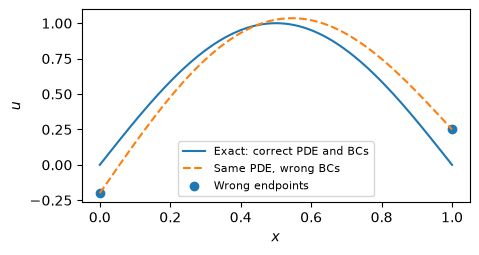

Affine-shift boundary values: -0.20 +0.25


In [7]:
# Even a function with the EXACT PDE residual may have incorrect endpoints.
# Any ax + b disappears after two derivatives, so the PDE cannot detect it.
x_illustration = x_plot.numpy().ravel()
u_target = np.sin(PI * x_illustration)
u_affine = u_target + 0.45 * x_illustration - 0.20
fig, ax = plt.subplots(figsize=(5.0, 2.5))
ax.plot(x_illustration, u_target, label='Exact: correct PDE and BCs')
ax.plot(x_illustration, u_affine, '--', label='Same PDE, wrong BCs')
ax.scatter([0.0, 1.0], [u_affine[0], u_affine[-1]], label='Wrong endpoints')
ax.set(xlabel='$x$', ylabel='$u$')
ax.legend(fontsize=8)
plt.show()
print('Affine-shift boundary values:', f'{u_affine[0]:+.2f}', f'{u_affine[-1]:+.2f}')

Hard: (0.00025830703089013696, 0.024921180680394173, 0.0) wall time=0.79s
Soft: (0.0018861216958612204, 0.05078643932938576, 0.002477191388607025)
Step    1/900: PDE=4.62e+01, BC=4.01e-02, total=4.62e+01
Step  300/900: PDE=1.27e-02, BC=2.50e+00, total=1.52e-02
Step  600/900: PDE=1.73e-03, BC=1.29e+00, total=3.02e-03
Step  900/900: PDE=6.66e-04, BC=8.10e-01, total=1.48e-03

Model                 rel L2      RMS residual     max |boundary u|
Soft (weight 10)        1.89e-03      5.08e-02         2.48e-03
Soft (weight 1e-3)      8.75e-01      3.21e-02         1.21e+00
Hard (exact BC)         2.58e-04      2.49e-02         0.00e+00


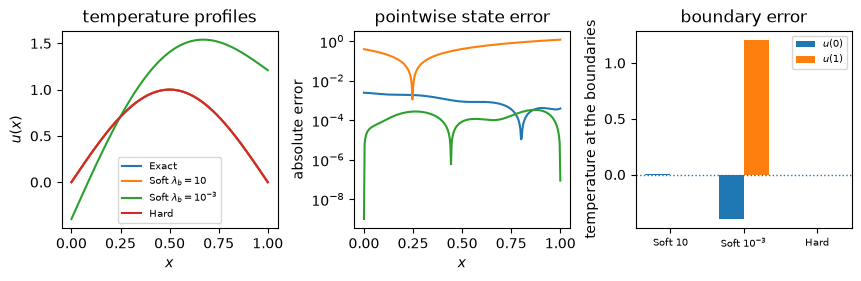

In [8]:
class HardPoisson(nn.Module):
    """Enforce homogeneous Dirichlet BCs by construction."""
    def __init__(self):
        super().__init__()
        self.net = make_mlp()

    def forward(self, x):
        
        # The factor x(1-x) vanishes exactly at both endpoints,
        # regardless of the neural network parameters.
        return x * (1.0 - x) * self.net(x)


def train_hard(model, steps=900, n_f=64):
    """Train only on the PDE residual: no boundary penalty is needed."""
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    history = []
    start = time.perf_counter()
    for _ in range(steps):
        x = torch.rand(n_f, 1, device=device).requires_grad_(True)
        u = model(x)
        loss = (-derivative(derivative(u, x), x) - source(x)).square().mean()
        opt.zero_grad(); loss.backward(); opt.step()
        history.append(loss.detach().item())
    return history, time.perf_counter()-start

hard_model = HardPoisson()
# Hard constraints should hold even BEFORE the network is trained.
with torch.no_grad():
    assert torch.all(hard_model(torch.tensor([[0.0], [1.0]])) == 0.0)
hard_history, hard_time = train_hard(hard_model)
print('Hard:', assess_poisson(hard_model), f'wall time={hard_time:.2f}s')
print('Soft:', (soft_error, soft_residual, soft_bc_error))

# A weak-penalty control uses the same starting weights and collocation sequence
# as the ordinary soft model. Only the BC weight changes.
weak_soft_model = make_mlp()
weak_soft_model.load_state_dict(soft_initial_state)
weak_logs, weak_time = train_poisson(weak_soft_model, bc_weight=1e-3)

# A compact numerical table makes endpoint violations impossible to overlook.
print('\nModel                 rel L2      RMS residual     max |boundary u|')
for name, model in [('Soft (weight 10)', soft_model),
                    ('Soft (weight 1e-3)', weak_soft_model),
                    ('Hard (exact BC)', hard_model)]:
    e_state, e_pde, e_bc = assess_poisson(model)
    print(f'{name:22s} {e_state:9.2e}   {e_pde:11.2e}    {e_bc:13.2e}')

with torch.no_grad():
    u_weak_plot = weak_soft_model(x_plot).numpy().ravel()
    u_hard_plot = hard_model(x_plot).numpy().ravel()
plot_poisson_hard_soft(x_plot.numpy(), u_exact(x_plot).detach().numpy(),
                       u_soft, u_weak_plot, u_hard_plot)


**Answer.**

- Endpoint guarantee: the hard ansatz $u_\theta=x(1-x)N_\theta(x)$ satisfies both homogeneous Dirichlet conditions exactly, even at random initialization. No optimizer success is needed for that property.
- Weak boundary weight: $\lambda_b=10^{-3}$ can achieve a small PDE residual while retaining large endpoint mismatch because the loss barely penalizes its affine ambiguity.
- Why do two final curves overlap? Standard soft and hard enforcement can both accurately approximate the exact solution. Plotting pointwise errors and evaluating the endpoints are necessary to reveal their different *guarantees*.
- Measured comparison (this particular run): soft $\lambda_b=10$: state error $1.89\times10^{-3}$ and endpoint max $2.48\times10^{-3}$; soft $10^{-3}$: state error $0.875$ and endpoint max $1.21$; hard: state error $2.58\times10^{-4}$ and endpoint error exactly zero. 

## Bonus exercises 

- A. Change the `Tanh` activation to `ReLU` in the unconstrained field. ReLU networks are piecewise affine, so $u_{xx}=0$ almost everywhere away from kinks: a strong-form residual involving curvature cannot exploit them in the same way. Check the supplied derivative diagnostic. Is this a network expressivity issue, an automatic-differentiation bug, or a mismatch between the activation and PDE formulation?
- B. Change from resampled collocation points to a fixed set. Inspect the residual on points not used for training. Can minimizing an empirical residual over a finite set guarantee a small residual between those points?
- C. With same initialization and training, sweep $\lambda_b\in\{10^{-3},10^{-1},10,10^3\}$. Report boundary conditions mismatch, held-out PDE residual and state error. Why does the numerical value of the (weighted) total loss not provide a meaningful comparison across different penalty weights?
- D. Set $\lambda_b=0$. Identify the nonzero homogeneous solutions of $-u_{xx}=0$. Is the resulting ambiguity a failure of the neural network or a lack of information in the mathematical problem?

### Bonus A — Activation functions: can a ReLU network represent the PDE's curvature?

**Question.** Our PDE involves $u_{xx}$, while a standard ReLU MLP is piecewise affine in $x$. Away from ReLU kinks its second derivative is zero. Does automatic differentiation produce a meaningful second-order strong-form residual for that architecture?

**Controlled test.** Hold the network width, training budget, soft boundary weight and source fixed. Train a ReLU network and compare it to the trained `Tanh` network. Check the derivatives *before* training and the independent residual *after* training.

**Prediction to write down first:** with ReLU, do you expect $L_f$ to decrease from optimization? Why?

ReLU max |u_xx| before training: 0.0
Step    1/900: PDE=4.52e+01, BC=4.04e-03, total=4.52e+01
Step  300/900: PDE=5.10e+01, BC=1.39e-17, total=5.10e+01
Step  600/900: PDE=4.99e+01, BC=0.00e+00, total=4.99e+01
Step  900/900: PDE=5.41e+01, BC=0.00e+00, total=5.41e+01
Tanh: L2=0.00189, RMS residual=0.0508, BC=0.00248
ReLU: L2=1.01, RMS residual=6.97, BC=0


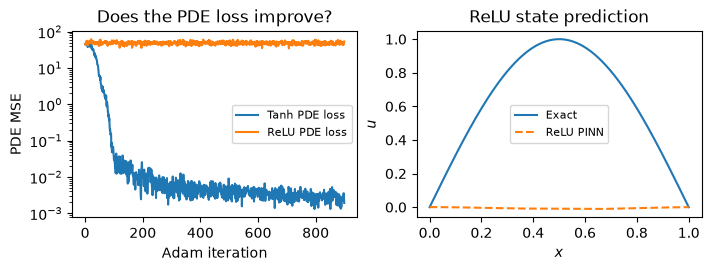

Check: ReLU pointwise PDE residual = -f(x) up to numerical precision.


In [9]:
# BONUS A — ReLU versus Tanh in a strong-form PINN.
# ReLU networks are piecewise affine in one dimension. Autograd treats their
# second derivative as zero almost everywhere (including its chosen subgradient
# at kinks). This is an architectural mismatch for our nonzero source f(x).
def make_relu_net():
    return nn.Sequential(
        nn.Linear(1, 32), nn.ReLU(),
        nn.Linear(32, 32), nn.ReLU(),
        nn.Linear(32, 1),
    )

relu_model = make_relu_net()
x_der = torch.linspace(0.015, 0.985, 73).view(-1, 1).requires_grad_(True)
relu_uxx = derivative(derivative(relu_model(x_der), x_der), x_der)
print('ReLU max |u_xx| before training:', relu_uxx.abs().max().item())

# Keep the same number of optimizer steps as the baseline Tanh network.
relu_logs, relu_time = train_poisson(relu_model, steps=900, bc_weight=10.0)
relu_err, relu_rms, relu_bc = assess_poisson(relu_model)
print(f'Tanh: L2={soft_error:.3g}, RMS residual={soft_residual:.3g}, BC={soft_bc_error:.3g}')
print(f'ReLU: L2={relu_err:.3g}, RMS residual={relu_rms:.3g}, BC={relu_bc:.3g}')

fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.6), constrained_layout=True)
ax[0].semilogy(soft_logs['pde'], label='Tanh PDE loss')
ax[0].semilogy(relu_logs['pde'], label='ReLU PDE loss')
ax[0].set(xlabel='Adam iteration', ylabel='PDE MSE', title='Does the PDE loss improve?')
ax[0].legend(fontsize=8)
with torch.no_grad():
    ax[1].plot(x_plot.numpy(), u_exact(x_plot).numpy(), label='Exact')
    ax[1].plot(x_plot.numpy(), relu_model(x_plot).numpy(), '--', label='ReLU PINN')
ax[1].set(xlabel='$x$', ylabel='$u$', title='ReLU state prediction')
ax[1].legend(fontsize=8)
plt.show()

# Analytical check: for the ReLU architecture, -u_xx=0 at ordinary points,
# so its residual is just -f(x), independent of network weights.
x_dense = torch.linspace(0, 1, 301).view(-1, 1).requires_grad_(True)
relu_residual = -derivative(derivative(relu_model(x_dense), x_dense), x_dense) - source(x_dense)
assert np.allclose(relu_residual.detach().numpy(), -source(x_dense).detach().numpy(), atol=1e-5)
print('Check: ReLU pointwise PDE residual = -f(x) up to numerical precision.')

**Interpretation.** ReLU is not intrinsically unsuitable for every scientific ML problem, and PyTorch AD is not malfunctioning. The issue is the *strong-form second-derivative residual*: the piecewise-affine network has $u_{xx}=0$ almost everywhere, so changing its weights cannot reduce $|-u_{xx}-f|^2$ for this nonzero source. The boundary term can still train the weights, creating the misleading appearance of a successful optimization. By contrast, `Tanh` admits nonzero smooth curvature. A hard-constrained ansatz such as $x(1-x)N_\theta(x)$ changes the trial class, so the simple piecewise-affine argument does **not** apply unchanged to a hard-constrained ReLU network.

**Representative numerical result.** With this architecture and $\lambda_b=10$, the Tanh PINN had a held-out residual RMS near $0.051$ and a relative state error near $0.0019$. The ReLU PINN had residual RMS near $6.97$ and relative state error around $1.01$, despite satisfying the two endpoint penalties. The ReLU PDE loss fluctuated around the mean of $f(x)^2$ as the collocation batch changed; it was not being reduced by weight optimization. The numerical assertions independently verify $u_{xx}=0$ for the ReLU MLP at the sampled points.

### Bonus B — Collocation: is a low *training-point* residual reliable?

**Question.** The continuous equation holds at every $x\in(0,1)$, but a PINN enforces it at finitely many points. Can a small training residual coexist with a much larger residual at previously unseen coordinates?

**Protocol.** Compare **six fixed points** against **six freshly resampled points per iteration**, using the same network initialization, boundary weight, and number of optimizer updates. Evaluate both models on a dense, common validation grid. The deliberately small sample budget makes this a stress test; the relative ranking may vary with initialization.

Step    1/900: PDE=4.57e+01, BC=4.01e-02, total=4.61e+01
Step  300/900: PDE=1.54e-04, BC=3.52e-08, total=1.54e-04
Step  600/900: PDE=2.93e-06, BC=5.86e-11, total=2.94e-06
Step  900/900: PDE=1.39e-06, BC=5.36e-11, total=1.39e-06
Step    1/900: PDE=5.51e+01, BC=4.01e-02, total=5.55e+01
Step  300/900: PDE=8.59e-03, BC=6.10e-05, total=9.20e-03
Step  600/900: PDE=4.01e-03, BC=4.07e-05, total=4.42e-03
Step  900/900: PDE=6.73e-03, BC=8.65e-06, total=6.82e-03
Fixed     : RMS at six fixed x=1.178e-03; fresh-grid RMS=1.154e-01; relative state error=9.379e-04
Resampled : RMS at six fixed x=5.047e-02; fresh-grid RMS=5.694e-02; relative state error=6.491e-03


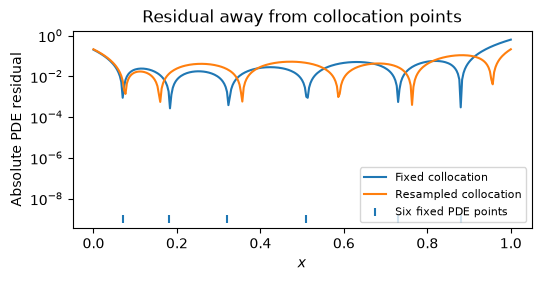

In [10]:
# BONUS B — Fixed versus resampled collocation.
# The sampled points, rather than a finite-difference mesh, approximate the
# continuous squared-residual integral. Here we hold the sampling budget fixed.
fixed_x = torch.tensor([0.07, 0.18, 0.32, 0.51, 0.73, 0.88]).view(-1, 1)
fixed_model = make_mlp()
fixed_model.load_state_dict(soft_initial_state)
resampled_model = make_mlp()
resampled_model.load_state_dict(soft_initial_state)

fixed_logs, _ = train_poisson(fixed_model, steps=900, n_f=6, bc_weight=10.0,
                              fixed_x=fixed_x)
resampled_logs, _ = train_poisson(resampled_model, steps=900, n_f=6, bc_weight=10.0)

def residual_at(model, x_values):
    """Compute the PDE residual at evaluation coordinates (with input AD)."""
    xx = x_values.detach().clone().requires_grad_(True)
    return (-derivative(derivative(model(xx), xx), xx) - source(xx)).detach().ravel()

x_validation = torch.linspace(0, 1, 301).view(-1, 1)
for name, model in [('Fixed', fixed_model), ('Resampled', resampled_model)]:
    r_train = residual_at(model, fixed_x)
    r_val = residual_at(model, x_validation)
    print(f'{name:10s}: RMS at six fixed x={r_train.square().mean().sqrt():.3e}; '
          f'fresh-grid RMS={r_val.square().mean().sqrt():.3e}; '
          f'relative state error={assess_poisson(model)[0]:.3e}')

fig, ax = plt.subplots(figsize=(5.3, 2.7), constrained_layout=True)
ax.semilogy(x_validation.ravel(), residual_at(fixed_model, x_validation).abs() + 1e-10,
            label='Fixed collocation')
ax.semilogy(x_validation.ravel(), residual_at(resampled_model, x_validation).abs() + 1e-10,
            label='Resampled collocation')
ax.scatter(fixed_x.ravel(), 1e-9 * np.ones(len(fixed_x)), marker='|',
           label='Six fixed PDE points')
ax.set(xlabel='$x$', ylabel='Absolute PDE residual', title='Residual away from collocation points')
ax.legend(fontsize=8)
plt.show()

**Interpretation.** A finite training set measures a *discrete* physics loss; it is not the same as the continuous residual norm. A fixed set can leave gaps where the residual is larger, while resampling explores different coordinates over time. The correct comparison is the fresh-grid RMS residual and the state error—not only the loss at the original six points. Neither strategy guarantees uniform residual control or convergence from one numerical run. The plotted vertical markers show *where* the fixed-point model was trained, which helps students interpret any peaks between them.

**Representative numerical result.** With six fixed collocation points, the RMS PDE residual *at those six points* was about $0.00118$, while the held-out-grid residual RMS was about $0.115$. The resampled model had held-out RMS about $0.0569$ (and about $0.0505$ at the six fixed coordinates, which it was **not** specifically trained to minimize). **Important nuance:** the fixed model nevertheless had lower relative *state* error in this run ($0.00094$ versus $0.00649$). A better residual on one metric does not automatically rank the state error for finite, imperfectly optimized networks. Report both quantities rather than declaring one strategy universally superior.

### Bonus C — Loss weights: is enforcing one condition enough?

**Question.** The boundary penalty $\lambda_b$ trades off two different numerical objectives. Does increasing it always improve the *field*? How can we compare runs fairly?

**Protocol.** Use identical initial weights and the same collocation pseudorandom sequence. Sweep $\lambda_b\in\{10^{-3},10^{-1},10,10^3\}$, then report the unweighted fresh-grid residual, endpoint error and relative state error. The baseline and weak-penalty models from Exercise 4 already cover two weights; we train only the remaining two.

Step    1/900: PDE=4.62e+01, BC=4.01e-02, total=4.62e+01
Step  300/900: PDE=1.71e-03, BC=4.03e-01, total=4.20e-02
Step  600/900: PDE=6.42e-04, BC=2.46e-02, total=3.10e-03
Step  900/900: PDE=2.11e-04, BC=1.31e-03, total=3.41e-04
Step    1/900: PDE=4.62e+01, BC=4.01e-02, total=8.63e+01
Step  300/900: PDE=1.02e-01, BC=3.68e-07, total=1.02e-01
Step  600/900: PDE=9.18e-04, BC=8.66e-09, total=9.27e-04
Step  900/900: PDE=4.18e-04, BC=8.83e-07, total=1.30e-03
BC weight  State rel.L2    Fresh PDE RMS    Max |boundary u|   Final weighted loss
   1e-03     8.750e-01       3.207e-02         1.209e+00        1.476e-03
   1e-01     3.068e-02       1.566e-02         4.151e-02        3.414e-04
   1e+01     1.886e-03       5.079e-02         2.477e-03        1.963e-03
   1e+03     1.154e-03       2.643e-02         1.256e-03        1.301e-03


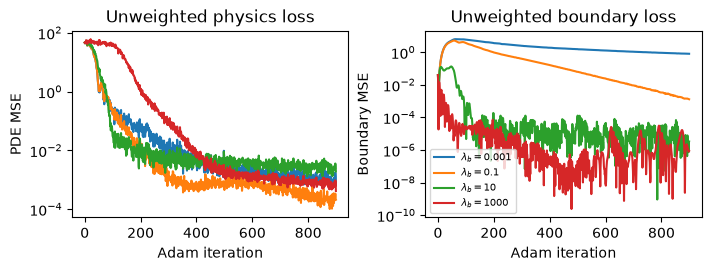

In [11]:
# BONUS C — Weight sweep, comparable initialization and collocation sequence.
weights = [1e-3, 1e-1, 10.0, 1e3]
weight_models = {1e-3: weak_soft_model, 10.0: soft_model}
weight_histories = {1e-3: weak_logs, 10.0: soft_logs}

for weight in (1e-1, 1e3):
    model = make_mlp()
    model.load_state_dict(soft_initial_state)
    history, _ = train_poisson(model, steps=900, bc_weight=weight)
    weight_models[weight] = model
    weight_histories[weight] = history

print('BC weight  State rel.L2    Fresh PDE RMS    Max |boundary u|   Final weighted loss')
weight_results = {}
for weight in weights:
    state, residual, bc_error = assess_poisson(weight_models[weight])
    objective = weight_histories[weight]['total'][-1]
    weight_results[weight] = (state, residual, bc_error, objective)
    print(f'{weight:8.0e}  {state:12.3e}   {residual:13.3e}   '
          f'{bc_error:15.3e}    {objective:13.3e}')

fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.6), constrained_layout=True)
for weight in weights:
    ax[0].semilogy(weight_histories[weight]['pde'], label=rf'$\lambda_b={weight:g}$')
    ax[1].semilogy(weight_histories[weight]['bc'], label=rf'$\lambda_b={weight:g}$')
ax[0].set(xlabel='Adam iteration', ylabel='PDE MSE', title='Unweighted physics loss')
ax[1].set(xlabel='Adam iteration', ylabel='Boundary MSE', title='Unweighted boundary loss')
ax[1].legend(fontsize=7)
plt.show()

**Interpretation.** A very small boundary weight allows a low-curvature-residual solution that may carry a large affine offset. A very large weight strongly prioritizes endpoint accuracy but can slow reduction of the PDE residual during a fixed optimization budget. The total losses reported above are not directly comparable across weights because their definitions differ. Compare physical error measures on the same held-out grid and retain the same initial state, sampling sequence and step count. The optimum can also depend on optimizer settings; no universal best penalty follows from this single sweep.

**Representative numerical result.** The boundary weights $10^{-3},10^{-1},10,10^3$ yielded approximate relative field errors $0.875,0.0307,0.00189,0.00153$ respectively in this run. At $\lambda_b=10^{-3}$ the maximum boundary error was $1.21$ despite a modest residual RMS of $0.032$. The large-weight run did *not* fail; it achieved maximum endpoint error about $0.00189$, with held-out residual RMS about $0.0266$. This is why the data support an optimization tradeoff, not a claim that a large penalty necessarily performs worse. Its final *weighted total loss* cannot be compared directly with losses using a different $\lambda_b$.

### Bonus D — Identifiability: what happens with no boundary conditions?

**Question.** Does minimizing $L_f$ alone identify the target temperature? The homogeneous equation $-v_{xx}=0$ has solutions $v(x)=ax+b$, so the prescribed Poisson equation admits the entire family $u_\star(x)+ax+b$ until additional information is supplied.

**Protocol.** Set $\lambda_b=0$ and train from the **same** initial weights. Fit the difference $u_\theta-u_\mathrm{exact}$ by an affine function on the validation grid. Show that the PDE residual can be small even if the state error is large.

Step    1/900: PDE=4.62e+01, BC=4.01e-02, total=4.62e+01
Step  300/900: PDE=1.33e-02, BC=4.45e+00, total=1.33e-02
Step  600/900: PDE=1.86e-03, BC=3.93e+00, total=1.86e-03
Step  900/900: PDE=7.46e-04, BC=3.76e+00, total=7.46e-04
No-BC model: relative state error=2.578e+00, fresh residual=3.396e-02, endpoint mismatch=2.579e+00
Affine error fit: a=+1.645, b=+0.934; non-affine remainder / ||u_exact||=2.552e-04


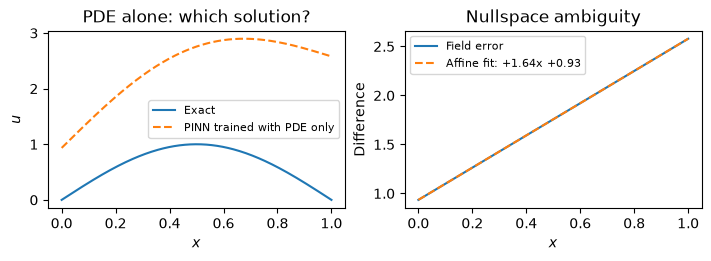

In [12]:
# BONUS D — Training without endpoint data: the PDE is underdetermined.
no_bc_model = make_mlp()
no_bc_model.load_state_dict(soft_initial_state)
no_bc_logs, _ = train_poisson(no_bc_model, steps=900, bc_weight=0.0)
err0, rms0, bc0 = assess_poisson(no_bc_model)

with torch.no_grad():
    xs = x_plot.numpy().ravel()
    exact_np = u_exact(x_plot).numpy().ravel()
    no_bc_np = no_bc_model(x_plot).numpy().ravel()

# Identify the two affine nullspace coefficients with a least-squares fit.
A = np.column_stack([xs, np.ones_like(xs)])
a_fit, b_fit = np.linalg.lstsq(A, no_bc_np - exact_np, rcond=None)[0]
shift = a_fit * xs + b_fit
remainder = np.linalg.norm((no_bc_np - exact_np) - shift) / np.linalg.norm(exact_np)
print(f'No-BC model: relative state error={err0:.3e}, fresh residual={rms0:.3e}, '
      f'endpoint mismatch={bc0:.3e}')
print(f'Affine error fit: a={a_fit:+.3f}, b={b_fit:+.3f}; '
      f'non-affine remainder / ||u_exact||={remainder:.3e}')

fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.5), constrained_layout=True)
ax[0].plot(xs, exact_np, label='Exact')
ax[0].plot(xs, no_bc_np, '--', label='PINN trained with PDE only')
ax[0].set(xlabel='$x$', ylabel='$u$', title='PDE alone: which solution?')
ax[0].legend(fontsize=8)
ax[1].plot(xs, no_bc_np - exact_np, label='Field error')
ax[1].plot(xs, shift, '--', label=rf'Affine fit: {a_fit:+.2f}x {b_fit:+.2f}')
ax[1].set(xlabel='$x$', ylabel='Difference', title='Nullspace ambiguity')
ax[1].legend(fontsize=8)
plt.show()

**Interpretation.** The lack of uniqueness is a property of the mathematical problem, not a failure of automatic differentiation or of Adam. With $\lambda_b=0$ the network can fit the equation while drifting along approximately affine solutions. The least-squares line estimates that uncontrolled nullspace component; the non-affine remainder measures imperfect optimization/approximation. Small residual + missing boundary data cannot certify the correct temperature field.

**Representative numerical result.** With zero boundary weight, the PINN had relative state error about $2.58$ even though its fresh-grid PDE residual RMS was about $0.0340$. Its error relative to the exact field was approximately $1.65x+0.934$; after subtracting that fitted affine shift, the remaining error had relative norm only about $2.55\times10^{-4}$. This is direct numerical evidence that the network can learn *one of the many PDE-consistent solutions* without identifying the boundary-value solution that we intended.

## Wrap-up

**1. Why can a PINN work without labeled temperatures?** The known forcing and differential equation constrain the neural trial function; endpoint data select a unique solution. The exact solution is only an independent verification tool.

**2. Why is a PDE residual not enough?** The differential operator has a nontrivial nullspace (affine functions), and enforcing the residual at finitely many collocation points introduces a separate sampling approximation. Both the conditions and evaluation points matter.

**3. What did the boundary experiment teach us?** Soft penalties create an optimization tradeoff. Hard constraints make admissibility exact *by design*, though they do not automatically guarantee a small interior residual or make every problem easier.

**4. Why discuss activation smoothness and weight balancing?** Because a PINN is simultaneously a physical formulation, a neural trial space, a numerical approximation of residual norms, and a nonconvex optimization procedure. Failures can originate in any of these four layers.
